# Tarea 3 — PyTorch

**Nombre del integrante:** Tomás Paraco

**Cédula del integrante:** 30497481

> Enunciado, rúbrica y nombres de los archivos `.pth` a entregar: ver `README.md` de esta carpeta.
> Antes del commit: *Restart & Run All* debe terminar sin errores y quedar en el menú.

## 1. Imports y constantes

In [1]:
import copy
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets, transforms

NOTEBOOK_PREFIX = "pytorch_fashion_3"
DATA_DIR = Path("data")
INPUT_SIZE = 28 * 28
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ORIGINAL_CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
                    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
SIMPLIFIED_CLASSES = ["Top", "Bottom", "Footwear", "Bag"]

# simplified class of each original label:
# Top = T-shirt, Pullover, Coat, Shirt; Bottom = Trouser, Dress;
# Footwear = Sandal, Sneaker, Ankle boot; Bag = Bag
TO_SIMPLIFIED = torch.tensor([0, 1, 0, 1, 0, 2, 0, 2, 3, 2])

# training options used when a network is created (they can be changed in the menu)
DEFAULT_TRAINING = {
    "optimizer": "adam",
    "learning_rate": 0.001,
    "weight_decay": 0.0,
    "batch_size": 64,
    "early_stopping": False,
    "patience": 3,
}

print("Device:", DEVICE)


Device: cpu


## 2. Datos (Fashion MNIST original y clases simplificadas)

In [2]:
def load_split(train):
    dataset = datasets.FashionMNIST(DATA_DIR, train=train, download=True,
                                    transform=transforms.ToTensor())
    # same values that ToTensor gives (pixels in [0, 1]), but converted all at once,
    # which is much faster than going image by image
    images = dataset.data.float().div(255).unsqueeze(1)
    return images, dataset.targets.clone()


def get_labels(labels, classification):
    if classification == "simplified":
        return TO_SIMPLIFIED[labels]
    return labels


def class_names(classification):
    if classification == "simplified":
        return SIMPLIFIED_CLASSES
    return ORIGINAL_CLASSES


train_images, train_labels = load_split(train=True)
test_images, test_labels = load_split(train=False)
print(f"Train: {len(train_images)} images, test: {len(test_images)} images")


100.0%
100.0%
100.0%
100.0%


Train: 60000 images, test: 10000 images


## 3. Modelos (rectangular y convolucional)

In [3]:
def output_size(classification):
    return len(class_names(classification))


def hidden_sizes(network_type, hidden_layers, neurons, n_outputs):
    if network_type == "convolutional":
        # linear interpolation between the input and the output layer,
        # so every layer has the same number of neurons less than the previous one
        return [round(INPUT_SIZE + (n_outputs - INPUT_SIZE) * i / (hidden_layers + 1))
                for i in range(1, hidden_layers + 1)]
    return [neurons] * hidden_layers


def build_model(sizes, n_outputs, dropout=0.0, batch_norm=False):
    layers = [nn.Flatten()]
    previous = INPUT_SIZE
    for size in sizes:
        layers.append(nn.Linear(previous, size))
        if batch_norm:
            layers.append(nn.BatchNorm1d(size))
        layers.append(nn.ReLU())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        previous = size
    layers.append(nn.Linear(previous, n_outputs))
    return nn.Sequential(*layers).to(DEVICE)


def create_network(network_type, hidden_layers, neurons, classification,
                   dropout=0.0, batch_norm=False):
    n_outputs = output_size(classification)
    sizes = hidden_sizes(network_type, hidden_layers, neurons, n_outputs)
    optimizations = {"dropout": dropout, "batch_norm": batch_norm}
    optimizations.update(DEFAULT_TRAINING)
    hyperparameters = {
        "network_type": network_type,
        "hidden_layers": hidden_layers,
        "neurons_per_layer": sizes,
        "epochs": 0,
        "classification": classification,
        "optimizations": optimizations,
    }
    model = build_model(sizes, n_outputs, dropout, batch_norm)
    return {"model": model, "hyperparameters": hyperparameters}


def describe(network):
    hp = network["hyperparameters"]
    opts = hp["optimizations"]
    sizes = [INPUT_SIZE] + hp["neurons_per_layer"] + [output_size(hp["classification"])]
    print(f"Red {hp['network_type']}, clasificación {hp['classification']}")
    print("  Capas: " + " -> ".join(str(s) for s in sizes))
    print(f"  Capas ocultas: {hp['hidden_layers']}, épocas entrenadas: {hp['epochs']}")
    print(f"  Dropout: {opts['dropout']}, batch norm: {opts['batch_norm']}")
    print(f"  Optimizador: {opts['optimizer']}, learning rate: {opts['learning_rate']}, "
          f"weight decay: {opts['weight_decay']}, batch size: {opts['batch_size']}")
    early = f"sí (paciencia {opts['patience']})" if opts["early_stopping"] else "no"
    print(f"  Early stopping: {early}")


## 4. Entrenar, probar, guardar y cargar

In [4]:
def make_optimizer(model, opts):
    if opts["optimizer"] == "sgd":
        return torch.optim.SGD(model.parameters(), lr=opts["learning_rate"],
                               momentum=0.9, weight_decay=opts["weight_decay"])
    return torch.optim.Adam(model.parameters(), lr=opts["learning_rate"],
                            weight_decay=opts["weight_decay"])


def run_epoch(model, loader, loss_fn, optimizer=None):
    # trains when an optimizer is given, otherwise only measures the loss
    training = optimizer is not None
    model.train(training)
    total_loss, count = 0.0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            loss = loss_fn(model(images), labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(labels)
            count += len(labels)
    return total_loss / count


def train(network, epochs):
    model, hp = network["model"], network["hyperparameters"]
    opts = hp["optimizations"]
    data = TensorDataset(train_images, get_labels(train_labels, hp["classification"]))

    val_loader = None
    if opts["early_stopping"]:
        # 10% of the training set is kept aside to decide when to stop
        val_size = len(data) // 10
        data, val_data = random_split(data, [len(data) - val_size, val_size])
        val_loader = DataLoader(val_data, batch_size=1000)
    loader = DataLoader(data, batch_size=opts["batch_size"], shuffle=True)

    optimizer = make_optimizer(model, opts)
    loss_fn = nn.CrossEntropyLoss()
    first_epoch = hp["epochs"] + 1
    train_losses, val_losses = [], []
    best_loss, best_state, bad_epochs = float("inf"), None, 0

    for _ in range(epochs):
        train_losses.append(run_epoch(model, loader, loss_fn, optimizer))
        hp["epochs"] += 1
        message = f"Epoch {hp['epochs']}: train loss {train_losses[-1]:.4f}"
        if val_loader is not None:
            val_losses.append(run_epoch(model, val_loader, loss_fn))
            message += f", validation loss {val_losses[-1]:.4f}"
        print(message)

        if val_loader is not None:
            if val_losses[-1] < best_loss:
                best_loss, bad_epochs = val_losses[-1], 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                bad_epochs += 1
                if bad_epochs >= opts["patience"]:
                    print(f"Early stopping: no improvement in {bad_epochs} epochs")
                    break

    if best_state is not None:
        model.load_state_dict(best_state)  # keep the weights with the best validation loss
    plot_losses(train_losses, val_losses, first_epoch)


def plot_losses(train_losses, val_losses, first_epoch):
    epochs = range(first_epoch, first_epoch + len(train_losses))
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, train_losses, marker="o", label="entrenamiento")
    if val_losses:
        plt.plot(epochs, val_losses, marker="o", label="validación")
    plt.title("Pérdida (loss) por época")
    plt.xlabel("Época")
    plt.ylabel("Cross entropy")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()


def predict(model, images):
    model.eval()
    predictions = []
    with torch.no_grad():
        for start in range(0, len(images), 1000):
            batch = images[start:start + 1000].to(DEVICE)
            predictions.append(model(batch).argmax(dim=1).cpu())
    return torch.cat(predictions)


def confusion_matrix(true, predicted, n_classes):
    # row = real class, column = predicted class
    counts = torch.bincount(true * n_classes + predicted, minlength=n_classes * n_classes)
    return counts.reshape(n_classes, n_classes)


def test(network):
    hp = network["hyperparameters"]
    names = class_names(hp["classification"])
    true = get_labels(test_labels, hp["classification"])
    predicted = predict(network["model"], test_images)
    matrix = confusion_matrix(true, predicted, len(names))

    correct = matrix.diag().float()
    accuracy = (correct.sum() / matrix.sum()).item()
    precision = correct / matrix.sum(dim=0).clamp(min=1).float()
    recall = correct / matrix.sum(dim=1).clamp(min=1).float()

    print(f"\nAccuracy: {accuracy:.2%}")
    print(f"Precision promedio: {precision.mean():.2%}")
    print(f"Recall promedio: {recall.mean():.2%}\n")
    print(f"{'Clase':<14}{'Precision':>10}{'Recall':>10}")
    for i, name in enumerate(names):
        print(f"{name:<14}{precision[i]:>10.2%}{recall[i]:>10.2%}")
    plot_confusion(matrix, names, accuracy)


def plot_confusion(matrix, names, accuracy):
    size = 8 if len(names) > 4 else 5
    fig, ax = plt.subplots(figsize=(size, size))
    ax.matshow(matrix, cmap="Blues")
    for row in range(len(names)):
        for col in range(len(names)):
            value = matrix[row, col].item()
            color = "white" if value > matrix.max().item() / 2 else "black"
            ax.text(col, row, str(value), ha="center", va="center", color=color)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names, rotation=45, ha="left")
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"Matriz de confusión (accuracy = {accuracy:.2%})")
    plt.show()


def save_network(network, path):
    torch.save({"state_dict": network["model"].state_dict(),
                "hyperparameters": network["hyperparameters"]}, path)


def load_network(path):
    checkpoint = torch.load(path, map_location=DEVICE)
    hp = checkpoint["hyperparameters"]
    opts = hp["optimizations"]
    for key, value in DEFAULT_TRAINING.items():
        opts.setdefault(key, value)
    model = build_model(hp["neurons_per_layer"], output_size(hp["classification"]),
                        opts["dropout"], opts["batch_norm"])
    model.load_state_dict(checkpoint["state_dict"])
    return {"model": model, "hyperparameters": hp}


## 5. Menú

La última celda deja el menú corriendo (crear/cargar, entrenar, probar, guardar, salir).
En cada pregunta, si se presiona Enter se usa el valor que aparece entre corchetes.

**Redes entregadas** (todas con Adam, learning rate 0.001 y batch size 64):

| Archivo | Capas | Optimizaciones | Épocas | Accuracy en prueba |
|---|---|---|---|---|
| `pytorch_fashion_3_original_rectangular.pth` | 784 → 256 → 256 → 10 | dropout 0.2 | 10 | 87.94% |
| `pytorch_fashion_3_original_convolutional.pth` | 784 → 526 → 268 → 10 | dropout 0.2 | 10 | 88.14% |
| `pytorch_fashion_3_simplified_rectangular.pth` | 784 → 128 → 4 | ninguna | 5 | 96.89% |
| `pytorch_fashion_3_simplified_convolutional.pth` | 784 → 394 → 4 | ninguna | 5 | 97.20% |


¿Qué desea hacer?
  1) Crear una nueva red
  2) Cargar una red de un archivo


Opción [1]:  2
Archivo .pth de la red:  pytorch_fashion_3_original_convolutional.pth



Red convolutional, clasificación original
  Capas: 784 -> 526 -> 268 -> 10
  Capas ocultas: 2, épocas entrenadas: 10
  Dropout: 0.2, batch norm: False
  Optimizador: adam, learning rate: 0.001, weight decay: 0.0, batch size: 64
  Early stopping: no

--- Menú ---
  1) Entrenar
  2) Probar con el conjunto de prueba
  3) Guardar la red (.pth)
  4) Optimizaciones de entrenamiento
  5) Crear o cargar otra red
  6) Salir


Opción [1]:  2



Accuracy: 88.14%
Precision promedio: 88.37%
Recall promedio: 88.14%

Clase          Precision    Recall
T-shirt/top       80.65%    86.30%
Trouser           99.28%    97.10%
Pullover          87.22%    71.00%
Dress             84.74%    91.10%
Coat              72.34%    88.40%
Sandal            96.22%    96.70%
Shirt             74.82%    63.00%
Sneaker           96.37%    92.90%
Bag               97.80%    97.60%
Ankle boot        94.28%    97.30%


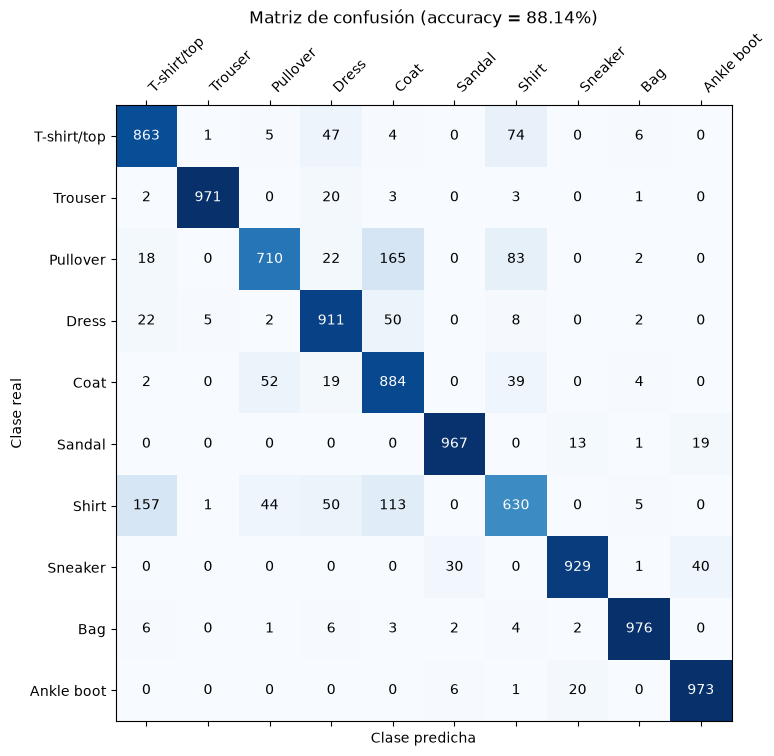


--- Menú ---
  1) Entrenar
  2) Probar con el conjunto de prueba
  3) Guardar la red (.pth)
  4) Optimizaciones de entrenamiento
  5) Crear o cargar otra red
  6) Salir


Opción [1]:  6


Fin del programa.


In [5]:
def ask_int(message, default, minimum=0):
    while True:
        text = input(f"{message} [{default}]: ").strip()
        if text == "":
            return default
        if text.isdigit() and int(text) >= minimum:
            return int(text)
        print(f"Escriba un número entero mayor o igual a {minimum}.")


def ask_float(message, default, minimum=0.0, maximum=None):
    while True:
        text = input(f"{message} [{default}]: ").strip().replace(",", ".")
        if text == "":
            return default
        try:
            value = float(text)
        except ValueError:
            print("Escriba un número.")
            continue
        if value < minimum or (maximum is not None and value > maximum):
            print(f"El valor debe estar entre {minimum} y {maximum}.")
            continue
        return value


def ask_yes_no(message, default):
    hint = "S/n" if default else "s/N"
    while True:
        text = input(f"{message} [{hint}]: ").strip().lower()
        if text == "":
            return default
        if text in ("s", "si", "sí"):
            return True
        if text in ("n", "no"):
            return False
        print("Responda s o n.")


def ask_option(message, options, default=1):
    # options is a list of texts; returns the chosen number (starting at 1)
    print(message)
    for i, text in enumerate(options, start=1):
        print(f"  {i}) {text}")
    while True:
        text = input(f"Opción [{default}]: ").strip()
        if text == "":
            return default
        if text.isdigit() and 1 <= int(text) <= len(options):
            return int(text)
        print(f"Escriba un número del 1 al {len(options)}.")


def ask_text(message, default=""):
    suffix = f" [{default}]" if default else ""
    text = input(f"{message}{suffix}: ").strip().strip('"')
    return text if text else default


def new_network_menu():
    print("\n--- Nueva red ---")
    classification = ["original", "simplified"][ask_option(
        "Clasificación:", ["Original (10 clases)", "Simplificada (4 clases)"]) - 1]
    network_type = ["rectangular", "convolutional"][ask_option(
        "Tipo de red:", ["Rectangular", "Convolucional (embudo por interpolación lineal)"]) - 1]
    hidden_layers = ask_int("Número de capas ocultas", 2)
    neurons = 512
    if network_type == "rectangular":
        neurons = ask_int("Neuronas por capa", 512, minimum=1)
    dropout = ask_float("Dropout (0 = desactivado)", 0.0, maximum=0.9)
    batch_norm = ask_yes_no("¿Usar batch normalization?", False)
    return create_network(network_type, hidden_layers, neurons, classification,
                          dropout, batch_norm)


def load_menu():
    while True:
        path = ask_text("Archivo .pth de la red")
        try:
            return load_network(path)
        except FileNotFoundError:
            print("No se encontró el archivo.")
        except Exception as error:
            print(f"No se pudo cargar la red: {error}")


def choose_network():
    option = ask_option("\n¿Qué desea hacer?", ["Crear una nueva red", "Cargar una red de un archivo"])
    network = new_network_menu() if option == 1 else load_menu()
    print()
    describe(network)
    return network


def optimizations_menu(network):
    opts = network["hyperparameters"]["optimizations"]
    print("\n--- Optimizaciones de entrenamiento ---")
    print("(dropout y batch normalization se eligen al crear la red)")
    opts["optimizer"] = ["adam", "sgd"][ask_option(
        "Optimizador:", ["Adam", "SGD con momentum"], 1 if opts["optimizer"] == "adam" else 2) - 1]
    opts["learning_rate"] = ask_float("Learning rate", opts["learning_rate"], minimum=1e-6)
    opts["weight_decay"] = ask_float("Weight decay (0 = desactivado)", opts["weight_decay"])
    opts["batch_size"] = ask_int("Batch size", opts["batch_size"], minimum=1)
    opts["early_stopping"] = ask_yes_no("¿Usar early stopping?", opts["early_stopping"])
    if opts["early_stopping"]:
        opts["patience"] = ask_int("Paciencia (épocas sin mejorar)", opts["patience"], minimum=1)


def main_menu():
    network = choose_network()
    while True:
        option = ask_option("\n--- Menú ---", [
            "Entrenar",
            "Probar con el conjunto de prueba",
            "Guardar la red (.pth)",
            "Optimizaciones de entrenamiento",
            "Crear o cargar otra red",
            "Salir",
        ])
        if option == 1:
            epochs = ask_int("Número de épocas", 10, minimum=1)
            train(network, epochs)
            describe(network)
        elif option == 2:
            test(network)
        elif option == 3:
            hp = network["hyperparameters"]
            default = f"{NOTEBOOK_PREFIX}_{hp['classification']}_{hp['network_type']}.pth"
            path = ask_text("Archivo donde guardar", default)
            save_network(network, path)
            print(f"Red guardada en {path}")
        elif option == 4:
            optimizations_menu(network)
            describe(network)
        elif option == 5:
            network = choose_network()
        else:
            print("Fin del programa.")
            break


main_menu()
